In [1]:
import sys
from pathlib import Path

package_root = str(Path.cwd().parent)
if package_root not in sys.path:
    sys.path.append(package_root)

In [2]:
from __future__ import annotations
import pandas as pd 
from typing import Dict, List, Tuple
from pathlib import Path
from collections.abc import Iterable
import matplotlib.pyplot as plt
import seaborn as sns
import os 
import time
import re
import numpy as np
from copy import deepcopy
from datetime import datetime
from typing import Any
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

In [3]:
DATASET_FOLDER = "../../../dataset/processed-data"
DEVICE_MAPPING_FOLDER = DATASET_FOLDER + "/device-mapping"
INPUT_FOLDER = DATASET_FOLDER + "/input-data"
DATASET1 = "dataset1"
DATASET2 = "dataset2"

In [4]:
MAPPING_LIST_1 = f"{DEVICE_MAPPING_FOLDER}/{DATASET1}/list_of_devices_processed.csv"
MAPPING_LIST_2 = f"{DEVICE_MAPPING_FOLDER}/{DATASET2}/list_of_devices_processed.csv"
INPUT_1 = f"{INPUT_FOLDER}/{DATASET1}"
INPUT_2 = f"{INPUT_FOLDER}/{DATASET2}"

In [5]:
csv_files_1 = [f"{INPUT_1}/{f.name}" for f in sorted(Path(INPUT_1).iterdir()) if f.is_file() and f.suffix == ".csv"]
for file in csv_files_1:
    print(file)

../../../dataset/processed-data/input-data/dataset1/16-09-23.csv
../../../dataset/processed-data/input-data/dataset1/16-09-24.csv
../../../dataset/processed-data/input-data/dataset1/16-09-25.csv
../../../dataset/processed-data/input-data/dataset1/16-09-26.csv
../../../dataset/processed-data/input-data/dataset1/16-09-27.csv
../../../dataset/processed-data/input-data/dataset1/16-09-28.csv
../../../dataset/processed-data/input-data/dataset1/16-09-29.csv
../../../dataset/processed-data/input-data/dataset1/16-09-30.csv
../../../dataset/processed-data/input-data/dataset1/16-10-01.csv
../../../dataset/processed-data/input-data/dataset1/16-10-02.csv
../../../dataset/processed-data/input-data/dataset1/16-10-03.csv
../../../dataset/processed-data/input-data/dataset1/16-10-04.csv
../../../dataset/processed-data/input-data/dataset1/16-10-05.csv
../../../dataset/processed-data/input-data/dataset1/16-10-06.csv
../../../dataset/processed-data/input-data/dataset1/16-10-07.csv
../../../dataset/processe

In [6]:
device_mapping_1 = pd.read_csv(MAPPING_LIST_1)
device_dict_1 = (
    device_mapping_1
    .set_index("mac_address")
    .drop(columns=["mac_address"], errors="ignore")
    .to_dict(orient="index")
)
device_dict_1

{'d0:52:a8:00:67:5e': {'device_name': 'Smart Things',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'hub',
  'vendor': 'Samsung SmartThings'},
 '44:65:0d:56:cc:d3': {'device_name': 'Amazon Echo',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'smart speaker',
  'vendor': 'Amazon'},
 '70:ee:50:18:34:43': {'device_name': 'Netatmo Welcome',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Netatmo'},
 'f4:f2:6d:93:51:f1': {'device_name': 'TP-Link Day Night Cloud camera',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'TP-Link'},
 '00:16:6c:ab:6b:88': {'device_name': 'Samsung SmartCam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Samsung'},
 '30:8c:fb:2f:e4:b2': {'device_name': 'Dropcam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Dropcam'},
 '00:62:6e:51:27:2e': {'device_name': 'Insteon Camera',
  'ip_address': nan,
 

In [7]:
FEATURE_COLUMNS = [
    "packet_count",
    "total_bytes",
]

DEVICE_COLUMN = "eth.src"          # Replace with "eth.src" if applicable
TIME_COLUMN = "timestamp"
LABEL_COLUMN = "is_iot_device"

N_SPLITS = 5
N_VOTING_WINDOWS = 7
MINIMUM_PACKET_COUNT = 1
MAX_TRAIN_WINDOWS_PER_DEVICE = 40_000
RANDOM_STATE = 42
WINDOW_SECONDS = 4

In [8]:
pd.set_option("display.max_colwidth", None)

In [9]:
def calculate_features(
    file_paths: Iterable[str],
    window: float,
) -> Tuple[pd.DataFrame, float]:
    if window <= 0:
        raise ValueError("window must be greater than 0.")

    columns = [
        "frame.time_epoch",
        "frame.len",
        "eth.src",
    ]

    all_features = []
    start_time = time.perf_counter()

    for file_path in file_paths:
        df = pd.read_csv(
            file_path,
            usecols=columns,
            dtype={
                "frame.time_epoch": "float64",
                "frame.len": "int32",
                "eth.src": "category",
            },
        )

        if df.empty:
            continue

        capture_start = df["frame.time_epoch"].min()

        df["window"] = (
            (df["frame.time_epoch"] - capture_start) // window
        ).astype("int32")

        basic_features = (
            df.groupby(
                ["window", "eth.src"],
                sort=False,
                observed=True,
            )
            .agg(
                packet_count=("frame.len", "size"),
                total_bytes=("frame.len", "sum"),

                # Timestamp of the first packet from this device
                # within this window.
                timestamp=("frame.time_epoch", "min"),
            )
            .reset_index()
        )

        # Retain which input capture produced each feature row.
        basic_features["capture_id"] = Path(file_path).stem

        all_features.append(basic_features)

    elapsed_time = time.perf_counter() - start_time

    if not all_features:
        empty_result = pd.DataFrame(
            columns=[
                "capture_id",
                "window",
                "timestamp",
                "eth.src",
                "packet_count",
                "total_bytes",
            ]
        )
        return empty_result, elapsed_time

    result = pd.concat(
        all_features,
        ignore_index=True,
    )

    result["packet_count"] = result["packet_count"].astype("int32")
    result["total_bytes"] = result["total_bytes"].astype("int64")

    result = result.sort_values(
        ["timestamp", "eth.src"],
        ignore_index=True,
    )

    return result, elapsed_time

In [10]:
def label_features(features: pd.DataFrame, device_mapping: Dict[str, Dict[str, str]]) -> pd.DataFrame:
    # Check if eth.src is in device_mapping, and get label is_iot_device, device_type, and vendor
    features["is_iot_device"] = features["eth.src"].apply(
        lambda x: device_mapping.get(x, {}).get("is_iot_device", 0)
    )
    features["device_type"] = features["eth.src"].apply(
        lambda x: device_mapping.get(x, {}).get("device_type", "unknown")
    )
    features["vendor"] = features["eth.src"].apply(
        lambda x: device_mapping.get(x, {}).get("vendor", "unknown")
    )
    return features
    

In [11]:
features1, _ = calculate_features(csv_files_1, window=WINDOW_SECONDS)

In [12]:
features1.head(10)

,window,eth.src,packet_count,total_bytes,timestamp,capture_id
0,0,18:b7:9e:02:20:44,3,202,1.474553e+09,16-09-23
1,0,14:cc:20:51:33:ea,18,1449,1.474553e+09,16-09-23
2,0,d0:52:a8:00:67:5e,3,259,1.474553e+09,16-09-23
3,0,70:ee:50:18:34:43,3,284,1.474553e+09,16-09-23
4,0,ec:1a:59:79:f4:89,1,42,1.474553e+09,16-09-23
5,0,30:8c:fb:2f:e4:b2,4,624,1.474553e+09,16-09-23
6,0,00:24:e4:11:18:a8,2,132,1.474553e+09,16-09-23
7,1,08:21:ef:3b:fc:e3,2,108,1.474553e+09,16-09-23
8,1,14:cc:20:51:33:ea,7,495,1.474553e+09,16-09-23
9,1,f4:f2:6d:93:51:f1,2,214,1.474553e+09,16-09-23


In [13]:
result = (
    features1.groupby("eth.src", observed=True)["capture_id"]
      .unique()
      .reset_index()
)
result

,eth.src,capture_id
0,00:16:6c:ab:6b:88,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
1,00:24:e4:10:ee:4c,[16-10-07]
2,00:24:e4:11:18:a8,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07]"
3,00:24:e4:1b:6f:96,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
4,00:24:e4:20:28:c6,"[16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
5,00:62:6e:51:27:2e,"[16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
6,08:21:ef:3b:fc:e3,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
7,14:cc:20:51:33:ea,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
8,18:b4:30:25:be:e4,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11]"
9,18:b7:9e:02:20:44,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"


- Looks like we can't get enough devices, looks like there are some devices that doesn't have enough window. Let's check that

In [14]:
labled_features1 = label_features(features1, device_dict_1)

In [15]:
df = labled_features1.copy()

In [16]:
min_windows = N_VOTING_WINDOWS + 1

# Count windows for each (eth.src, capture_id)
capture_counts = (
    df.groupby(["eth.src", "capture_id"])
      .size()
      .reset_index(name="window_count")
)

# For each device, check whether ANY capture_id has enough windows
device_validity = (
    capture_counts
    .groupby("eth.src")["window_count"]
    .max()
)

# Devices where NONE of the capture_ids have enough windows
devices_to_drop = device_validity[
    device_validity < min_windows
].index

# Print information about dropped devices
dropped_device_info = (
    df[df["eth.src"].isin(devices_to_drop)]
    [["eth.src", "is_iot_device", "device_type", "vendor"]]
    .drop_duplicates()
    .sort_values("eth.src")
)

print("Dropped devices:")
print(dropped_device_info.to_string(index=False))

# Show capture/window counts for those dropped devices
print("\nCapture details:")
print(
    capture_counts[
        capture_counts["eth.src"].isin(devices_to_drop)
    ].to_string(index=False)
)

# Drop the devices completely
df_filtered = df[
    ~df["eth.src"].isin(devices_to_drop)
].copy()

remaining_device_info = (
    df_filtered[
        ["eth.src", "is_iot_device", "device_type", "vendor"]
    ]
    .drop_duplicates()
    .sort_values("eth.src")
)

print("\nRemaining devices:")
print(remaining_device_info.to_string(index=False))

print(f"\nNumber of remaining devices: {remaining_device_info['eth.src'].nunique()}")

# Optional summary counts
print("\nRemaining devices by IoT label:")
print(
    remaining_device_info["is_iot_device"]
    .value_counts(dropna=False)
)

print("\nRemaining devices by device type:")
print(
    remaining_device_info["device_type"]
    .value_counts(dropna=False)
)


Dropped devices:
          eth.src  is_iot_device device_type  vendor
8a:05:81:fa:cc:14              0     unknown unknown
d2:13:91:23:2a:58              0     unknown unknown

Capture details:
          eth.src capture_id  window_count
8a:05:81:fa:cc:14   16-09-28             4
d2:13:91:23:2a:58   16-09-28             4

Remaining devices:
          eth.src  is_iot_device            device_type              vendor
00:16:6c:ab:6b:88              1                 camera             Samsung
00:24:e4:10:ee:4c              0                unknown             unknown
00:24:e4:11:18:a8              1           baby monitor            Withings
00:24:e4:1b:6f:96              1            smart scale            Withings
00:24:e4:20:28:c6              1           sleep sensor            Withings
00:62:6e:51:27:2e              1                 camera             Insteon
08:21:ef:3b:fc:e3              0                unknown             unknown
14:cc:20:51:33:ea              0                u

In [17]:
df_filtered.head(5)

,window,eth.src,packet_count,total_bytes,timestamp,capture_id,is_iot_device,device_type,vendor
0,0,18:b7:9e:02:20:44,3,202,1.474553e+09,16-09-23,1,smart speaker,Invoxia
1,0,14:cc:20:51:33:ea,18,1449,1.474553e+09,16-09-23,0,unknown,unknown
2,0,d0:52:a8:00:67:5e,3,259,1.474553e+09,16-09-23,1,hub,Samsung SmartThings
3,0,70:ee:50:18:34:43,3,284,1.474553e+09,16-09-23,1,camera,Netatmo
4,0,ec:1a:59:79:f4:89,1,42,1.474553e+09,16-09-23,1,smart switch,Belkin


In [18]:
len(df_filtered)

2751361

In [19]:
def select_voting_window_indices(
    df: pd.DataFrame,
    N_VOTING_WINDOWS: int,
    random_state: int | None = None,
) -> list[int]:

    rng = np.random.default_rng(random_state)

    min_windows = N_VOTING_WINDOWS + 1
    selected_indices = []

    for eth_src, device_df in df.groupby("eth.src", observed=True):

        capture_counts = (
            device_df.groupby("capture_id", observed=True)
            .size()
        )

        eligible_capture_ids = capture_counts[
            capture_counts >= min_windows
        ].index.to_numpy()

        if len(eligible_capture_ids) == 0:
            continue

        # Randomly choose one eligible capture
        selected_capture_id = rng.choice(eligible_capture_ids)

        # Sort windows while preserving original dataframe indices
        capture_df = (
            device_df[
                device_df["capture_id"] == selected_capture_id
            ]
            .sort_values("window")
        )

        num_windows = len(capture_df)

        max_start = num_windows - N_VOTING_WINDOWS

        start_idx = rng.integers(
            low=0,
            high=max_start + 1,
        )

        end_idx = start_idx + N_VOTING_WINDOWS

        # Get original dataframe indices
        indices = capture_df.iloc[start_idx:end_idx].index.tolist()

        selected_indices.extend(indices)

    return selected_indices

In [20]:
def create_under_sampler(random_seed: int = 42) -> RandomUnderSampler:
    """
    Create a RandomUnderSampler for undersampling the majority class.

    Args:
        random_seed (int): Random seed for reproducibility.

    Returns:
        RandomUnderSampler: An instance of the RandomUnderSampler.
    """
    return RandomUnderSampler(random_state=random_seed)

def create_decision_tree(random_seed: int = 42) -> DecisionTreeClassifier:
    return DecisionTreeClassifier(
        criterion="gini",
        splitter="best",
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        min_weight_fraction_leaf=0.0,
        max_features=None,
        max_leaf_nodes=None,
        min_impurity_decrease=0.0,
        class_weight=None,
        random_state=random_seed,
    )

In [21]:
val_indices = select_voting_window_indices(
    df_filtered,
    N_VOTING_WINDOWS,
    random_state=42,
)

val_df = df_filtered.loc[val_indices]

In [22]:
train_indices = df_filtered.index.difference(val_indices)

In [23]:
len(val_indices), len(train_indices), len(df_filtered)

(224, 2751137, 2751361)

In [24]:
train_df, val_df = df_filtered.loc[train_indices], df_filtered.loc[val_indices]
X_train = train_df[FEATURE_COLUMNS]
y_train = train_df[LABEL_COLUMN]
X_val = val_df[FEATURE_COLUMNS]
y_val = val_df[LABEL_COLUMN]

In [25]:
sampler = create_under_sampler(random_seed=RANDOM_STATE)
X_train_resampled, y_train_resampled = sampler.fit_resample(X_train, y_train)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_resampled)
X_val_scaled = scaler.transform(X_val)

model = create_decision_tree(random_seed=RANDOM_STATE)
model.fit(X_train_scaled, y_train_resampled)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [26]:
each_window_pred = model.predict(X_val_scaled)

In [27]:
val_df["prediction"] = each_window_pred

In [28]:
val_df.head(10)

,window,eth.src,packet_count,total_bytes,timestamp,capture_id,is_iot_device,device_type,vendor,prediction
233381,16502,00:16:6c:ab:6b:88,14,6941,1.474705e+09,16-09-24,1,camera,Samsung,1
233417,16508,00:16:6c:ab:6b:88,2,254,1.474705e+09,16-09-24,1,camera,Samsung,1
233422,16509,00:16:6c:ab:6b:88,1,42,1.474705e+09,16-09-24,1,camera,Samsung,1
233427,16510,00:16:6c:ab:6b:88,14,6941,1.474705e+09,16-09-24,1,camera,Samsung,1
233443,16512,00:16:6c:ab:6b:88,3,218,1.474705e+09,16-09-24,1,camera,Samsung,1
233446,16513,00:16:6c:ab:6b:88,1,86,1.474705e+09,16-09-24,1,camera,Samsung,1
233459,16514,00:16:6c:ab:6b:88,1,46,1.474705e+09,16-09-24,1,camera,Samsung,1
2112053,13864,00:24:e4:10:ee:4c,1,66,1.475814e+09,16-10-07,0,unknown,unknown,1
2112068,13866,00:24:e4:10:ee:4c,2,126,1.475814e+09,16-10-07,0,unknown,unknown,1
2112079,13867,00:24:e4:10:ee:4c,2,126,1.475814e+09,16-10-07,0,unknown,unknown,1


In [29]:
def majority_vote(predictions: list[float]) -> int:
    """
    Perform majority voting on a list of predictions.

    Args:
        predictions (list[int]): List of predictions (0 or 1).

    Returns:
        int: The majority vote result (0 or 1). In case of a tie, returns 1.
    """
    if len(predictions) == 0:
        raise ValueError("The probabilities list is empty.")

    avg_probability = np.mean(predictions)
    return int(avg_probability >= 0.5)

In [30]:
prediction_by_device = (
    val_df.groupby("eth.src")["prediction"]
    .apply(list)
    .reset_index()
)
predict_and_true_by_device = label_features(prediction_by_device, device_dict_1)
display(predict_and_true_by_device)

,eth.src,prediction,is_iot_device,device_type,vendor
0,00:16:6c:ab:6b:88,"[1, 1, 1, 1, 1, 1, 1]",1,camera,Samsung
1,00:24:e4:10:ee:4c,"[1, 1, 1, 1, 1, 1, 1]",0,unknown,unknown
2,00:24:e4:11:18:a8,"[1, 1, 1, 1, 1, 1, 1]",1,baby monitor,Withings
3,00:24:e4:1b:6f:96,"[1, 0, 0, 1, 0, 0, 1]",1,smart scale,Withings
4,00:24:e4:20:28:c6,"[1, 1, 1, 1, 1, 1, 1]",1,sleep sensor,Withings
5,00:62:6e:51:27:2e,"[1, 1, 1, 1, 1, 1, 1]",1,camera,Insteon
6,08:21:ef:3b:fc:e3,"[0, 0, 0, 0, 0, 0, 1]",0,unknown,unknown
7,14:cc:20:51:33:ea,"[0, 0, 0, 0, 0, 0, 0]",0,unknown,unknown
8,18:b4:30:25:be:e4,"[0, 0, 0, 1, 1, 1, 0]",1,smoke alarm,Nest
9,18:b7:9e:02:20:44,"[1, 1, 1, 1, 1, 1, 1]",1,smart speaker,Invoxia


In [31]:
predict_and_true_by_device["aggregated_prediction"] = (
    predict_and_true_by_device["prediction"]
    .apply(majority_vote)
)

In [32]:
predict_and_true_by_device[["eth.src",  "prediction", "is_iot_device", "aggregated_prediction"]]

,eth.src,prediction,is_iot_device,aggregated_prediction
0,00:16:6c:ab:6b:88,"[1, 1, 1, 1, 1, 1, 1]",1,1
1,00:24:e4:10:ee:4c,"[1, 1, 1, 1, 1, 1, 1]",0,1
2,00:24:e4:11:18:a8,"[1, 1, 1, 1, 1, 1, 1]",1,1
3,00:24:e4:1b:6f:96,"[1, 0, 0, 1, 0, 0, 1]",1,0
4,00:24:e4:20:28:c6,"[1, 1, 1, 1, 1, 1, 1]",1,1
5,00:62:6e:51:27:2e,"[1, 1, 1, 1, 1, 1, 1]",1,1
6,08:21:ef:3b:fc:e3,"[0, 0, 0, 0, 0, 0, 1]",0,0
7,14:cc:20:51:33:ea,"[0, 0, 0, 0, 0, 0, 0]",0,0
8,18:b4:30:25:be:e4,"[0, 0, 0, 1, 1, 1, 0]",1,0
9,18:b7:9e:02:20:44,"[1, 1, 1, 1, 1, 1, 1]",1,1


In [33]:
accuracy = accuracy_score(
    predict_and_true_by_device["is_iot_device"],
    predict_and_true_by_device["aggregated_prediction"]
)
accuracy

0.78125

# Trying different size of voting window

In [34]:
labeled_features_copy = labled_features1.copy()

In [35]:
MIN_VOTING_WINDOWS = 7
MAX_VOTING_WINDOWS = 51

In [36]:
def filter_devices_by_voting_windows(
    feature: pd.DataFrame,
    voting_window: int,
) -> pd.DataFrame:
    min_windows = voting_window + 1
    df = feature.copy()
    # Count windows for each (eth.src, capture_id)
    capture_counts = (
        df.groupby(["eth.src", "capture_id"])
        .size()
        .reset_index(name="window_count")
    )

    # For each device, check whether ANY capture_id has enough windows
    device_validity = (
        capture_counts
        .groupby("eth.src")["window_count"]
        .max()
    )

    # Devices where NONE of the capture_ids have enough windows
    devices_to_drop = device_validity[
        device_validity < min_windows
    ].index

    # Print information about dropped devices
    dropped_device_info = (
        df[df["eth.src"].isin(devices_to_drop)]
        [["eth.src", "is_iot_device", "device_type", "vendor"]]
        .drop_duplicates()
        .sort_values("eth.src")
    )

    # Drop the devices completely
    df_filtered = df[
        ~df["eth.src"].isin(devices_to_drop)
    ].copy()

    return df_filtered

In [37]:
def train_and_evaluate(train_df: pd.DataFrame, val_df: pd.DataFrame, majority_vote_rule) -> float:
    X_train = train_df[FEATURE_COLUMNS]
    y_train = train_df[LABEL_COLUMN]

    X_val = val_df[FEATURE_COLUMNS]
    y_val = val_df[LABEL_COLUMN]

    sampler = create_under_sampler(random_seed=RANDOM_STATE)

    X_train_resampled, y_train_resampled = sampler.fit_resample(
        X_train,
        y_train
    )

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train_resampled)
    X_val_scaled = scaler.transform(X_val)

    model = create_decision_tree(random_seed=RANDOM_STATE)

    model.fit(
        X_train_scaled,
        y_train_resampled
    )

    # Probability for each class
    each_window_proba = model.predict_proba(X_val_scaled)

    # Get probability of class 1
    class_1_index = np.where(model.classes_ == 1)[0][0]
    each_window_iot_proba = each_window_proba[:, class_1_index]

    # Avoid modifying the original validation dataframe
    val_df = val_df.copy()

    val_df["iot_probability"] = each_window_iot_proba

    # Group window probabilities by device
    prediction_by_device = (
        val_df.groupby("eth.src")["iot_probability"]
        .apply(list)
        .reset_index()
    )

    predict_and_true_by_device = label_features(
        prediction_by_device,
        device_dict_1
    )

    # Aggregate probabilities across voting windows
    predict_and_true_by_device["aggregated_prediction"] = (
        predict_and_true_by_device["iot_probability"]
        .apply(lambda x: majority_vote_rule(x))
    )

    accuracy = accuracy_score(
        predict_and_true_by_device["is_iot_device"],
        predict_and_true_by_device["aggregated_prediction"]
    )

    return accuracy

In [38]:
metric = []
for voting_window in range(MIN_VOTING_WINDOWS, MAX_VOTING_WINDOWS + 1):
    filtered_df = filter_devices_by_voting_windows(labeled_features_copy, voting_window)
    val_indices = select_voting_window_indices(
        filtered_df,
        voting_window,
        random_state=RANDOM_STATE,
    )

    train_indices = filtered_df.index.difference(val_indices)
    train_df, val_df = filtered_df.loc[train_indices], filtered_df.loc[val_indices]
    accuracy_point = train_and_evaluate(train_df, val_df, majority_vote)
    metric.append({"voting_window": voting_window, "accuracy": accuracy_point})

In [39]:
metric_df = pd.DataFrame(metric)

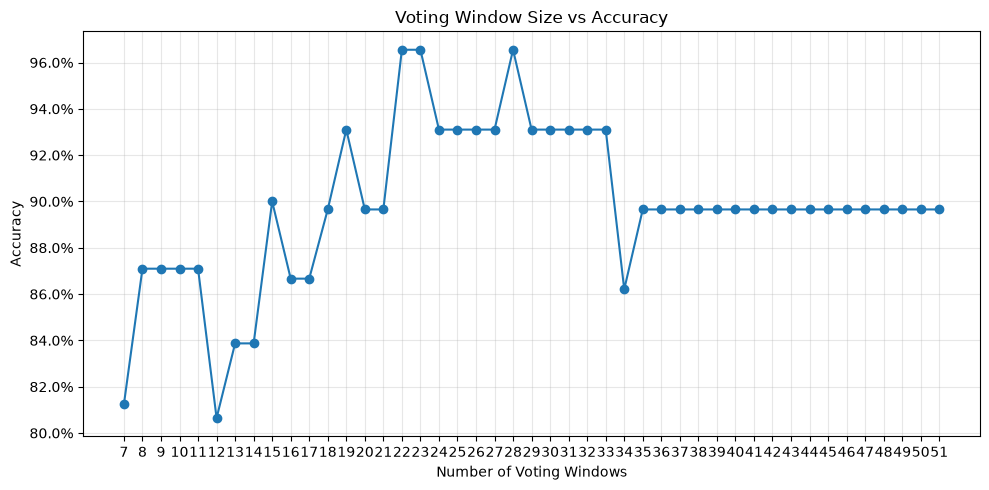

In [40]:
from matplotlib.ticker import PercentFormatter
plt.figure(figsize=(10, 5))

plt.plot(
    metric_df["voting_window"],
    metric_df["accuracy"],
    marker="o"
)

plt.xlabel("Number of Voting Windows")
plt.ylabel("Accuracy")
plt.title("Voting Window Size vs Accuracy")

plt.xticks(metric_df["voting_window"])
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Fix VOTING_WINDOW, try different window size

In [41]:
FIX_VOTING_WINDOWS = 31
MIN_WINDOWS = 3
MAX_WINDOWS = 30

In [43]:
metric = []
for window in range(MIN_WINDOWS, MAX_WINDOWS + 1):
    df, _ = calculate_features(csv_files_1, window=window)
    labeled_features = label_features(df, device_dict_1)

    filtered_df = filter_devices_by_voting_windows(labeled_features, voting_window)
    val_indices = select_voting_window_indices(
        filtered_df,
        FIX_VOTING_WINDOWS,
        random_state=RANDOM_STATE,
    )

    train_indices = filtered_df.index.difference(val_indices)
    train_df, val_df = filtered_df.loc[train_indices], filtered_df.loc[val_indices]
    accuracy_point = train_and_evaluate(train_df, val_df, majority_vote)
    metric.append({"window": window, "accuracy": accuracy_point})
    

In [44]:
metric_df = pd.DataFrame(metric)
metric_df

,window,accuracy
0,3,0.931034
1,4,0.931034
2,5,0.896552
3,6,0.896552
4,7,0.896552
5,8,0.896552
6,9,0.892857
7,10,0.892857
8,11,0.892857
9,12,0.892857


In [59]:
from matplotlib.ticker import PercentFormatter
plt.figure(figsize=(10, 5))

plt.plot(
    metric_df["window"],
    metric_df["accuracy"],
    marker="o"
)

plt.xlabel("Window Size")
plt.ylabel("Accuracy")
plt.title("Window Size vs Accuracy")

plt.xticks(metric_df["window"])
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

KeyError: 'window'

<Figure size 1000x500 with 0 Axes>

- Looks like the best parameter we can have is `window_size = 4` and `voting_window = 29`

# Try different majority voting rule

In [46]:
WINDOW_SECONDS

4

In [47]:
def average_probablity_vote(probabilities: list[float]) -> int:
    if len(probabilities) == 0:
        raise ValueError("The probabilities list is empty.")
    threshold = 0.7

    avg_probability = np.mean(probabilities)

    return int(avg_probability >= threshold)

In [48]:
features1, _ = calculate_features(csv_files_1, window=WINDOW_SECONDS)
labled_features = label_features(features1, device_dict_1)

In [49]:
labeled_features_copy = labled_features.copy()

In [50]:
metric = []
for voting_window in range(MIN_VOTING_WINDOWS, MAX_VOTING_WINDOWS + 1):
    filtered_df = filter_devices_by_voting_windows(labeled_features_copy, voting_window)
    val_indices = select_voting_window_indices(
        filtered_df,
        voting_window,
        random_state=RANDOM_STATE,
    )

    train_indices = filtered_df.index.difference(val_indices)
    train_df, val_df = filtered_df.loc[train_indices], filtered_df.loc[val_indices]
    accuracy_point = train_and_evaluate(train_df, val_df, average_probablity_vote)
    metric.append({"voting_window": voting_window, "accuracy": accuracy_point})

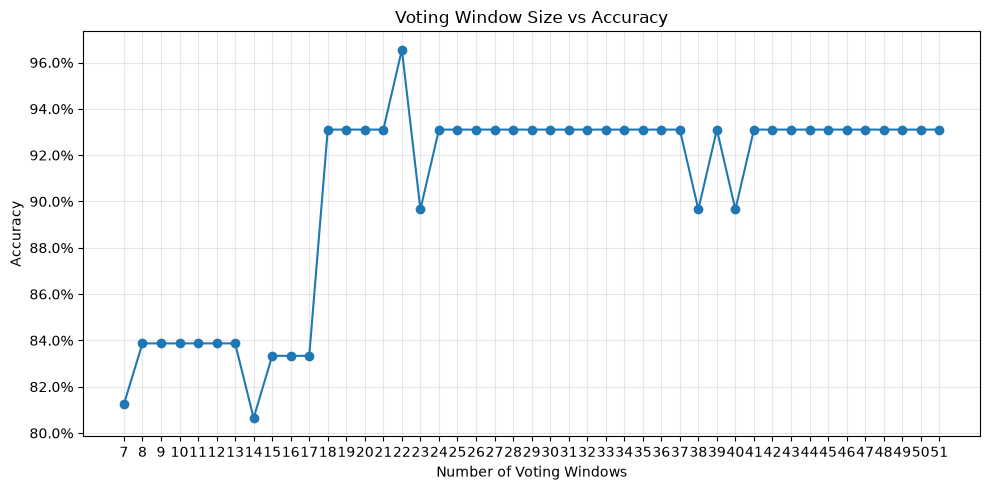

In [51]:
metric_df = pd.DataFrame(metric)
from matplotlib.ticker import PercentFormatter
plt.figure(figsize=(10, 5))

plt.plot(
    metric_df["voting_window"],
    metric_df["accuracy"],
    marker="o"
)

plt.xlabel("Number of Voting Windows")
plt.ylabel("Accuracy")
plt.title("Voting Window Size vs Accuracy")

plt.xticks(metric_df["voting_window"])
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

- I observe one pattern, the more threshold I increase, the higher accuracy I can get

# Try different threshold on the average probability with different window

In [52]:
thresholds = np.arange(0.3, 1.0, 0.05)
thresholds

array([0.3 , 0.35, 0.4 , 0.45, 0.5 , 0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 ,
       0.85, 0.9 , 0.95])

In [53]:
def average_probablity_vote_with_custom_threshold(probabilities: list[float], threshold: float) -> int:
    if len(probabilities) == 0:
        raise ValueError("The probabilities list is empty.")

    avg_probability = np.mean(probabilities)

    return int(avg_probability >= threshold)

In [54]:
def train_and_evaluate_with_different_threshold(train_df: pd.DataFrame, val_df: pd.DataFrame, majority_vote_rule, threshold_list: List[float]) -> Dict[float, float]:
    X_train = train_df[FEATURE_COLUMNS]
    y_train = train_df[LABEL_COLUMN]

    X_val = val_df[FEATURE_COLUMNS]
    y_val = val_df[LABEL_COLUMN]

    sampler = create_under_sampler(random_seed=RANDOM_STATE)

    X_train_resampled, y_train_resampled = sampler.fit_resample(
        X_train,
        y_train
    )

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train_resampled)
    X_val_scaled = scaler.transform(X_val)

    model = create_decision_tree(random_seed=RANDOM_STATE)

    model.fit(
        X_train_scaled,
        y_train_resampled
    )

    # Probability for each class
    each_window_proba = model.predict_proba(X_val_scaled)

    # Get probability of class 1
    class_1_index = np.where(model.classes_ == 1)[0][0]
    each_window_iot_proba = each_window_proba[:, class_1_index]

    # Avoid modifying the original validation dataframe
    val_df = val_df.copy()

    val_df["iot_probability"] = each_window_iot_proba

    # Group window probabilities by device
    prediction_by_device = (
        val_df.groupby("eth.src")["iot_probability"]
        .apply(list)
        .reset_index()
    )

    predict_and_true_by_device = label_features(
        prediction_by_device,
        device_dict_1
    )
    accuracies = {}
    for threshold in threshold_list:
        # Aggregate probabilities across voting windows
        predict_and_true_by_device[f"aggregated_prediction_{threshold}"] = (
            predict_and_true_by_device["iot_probability"]
            .apply(lambda x: majority_vote_rule(x, threshold))
        )

        accuracy = accuracy_score(
            predict_and_true_by_device["is_iot_device"],
            predict_and_true_by_device[f"aggregated_prediction_{threshold}"]
        )
        misclassified_eth_src = predict_and_true_by_device.loc[
            predict_and_true_by_device["is_iot_device"]
            != predict_and_true_by_device[f"aggregated_prediction_{threshold}"],
            "eth.src"
        ].tolist()

        total_device_count = predict_and_true_by_device["eth.src"].nunique()
        iot_device_count = predict_and_true_by_device.loc[
            predict_and_true_by_device["is_iot_device"] == 1,
            "eth.src"
        ].nunique()
        non_iot_device_count = predict_and_true_by_device.loc[
            predict_and_true_by_device["is_iot_device"] == 0,
            "eth.src"
        ].nunique()
        
        metadata = {
            "accuracy": accuracy, 
            "missclassified": misclassified_eth_src, 
            "total_device_count": total_device_count, 
            "iot_device_count": iot_device_count,
            "non_iot_device_count": non_iot_device_count
        }
        accuracies[threshold] = metadata

    return accuracies

In [55]:
labeled_features_copy = labled_features.copy()
all_devices = set(labeled_features_copy["eth.src"].unique())
metric = []
for voting_window in range(MIN_VOTING_WINDOWS, MAX_VOTING_WINDOWS + 1):
    metric_cur_window = []

    filtered_df = filter_devices_by_voting_windows(labeled_features_copy, voting_window)
    val_indices = select_voting_window_indices(
        filtered_df,
        voting_window,
        random_state=RANDOM_STATE + voting_window, # Increase the chance of not selecting the same window 
    )

    filtered_device_set = set(filtered_df["eth.src"].unique())
    dropped_device = all_devices - filtered_device_set
    dropped_iot_device, dropped_non_iot_device = [], []
    for mac in dropped_device:
        if mac in device_dict_1:
            dropped_iot_device.append((mac, device_dict_1[mac]["device_name"]))
        else:
            dropped_non_iot_device.append((mac, "unknown"))


    train_indices = filtered_df.index.difference(val_indices)
    train_df, val_df = filtered_df.loc[train_indices], filtered_df.loc[val_indices]
    accuracies = train_and_evaluate_with_different_threshold(train_df, val_df, average_probablity_vote_with_custom_threshold, thresholds)
    for threshold in accuracies:
        metadata = accuracies[threshold]
        metadata["dropped_iot_devices"] = dropped_iot_device
        metadata["dropped_non_iot_device"] = dropped_non_iot_device
        metadata["voting_window"] = voting_window
        metadata["threshold"] = threshold
        metric_cur_window.append(metadata)
    metric.extend(metric_cur_window)

In [56]:
metric_df = pd.DataFrame(metric)

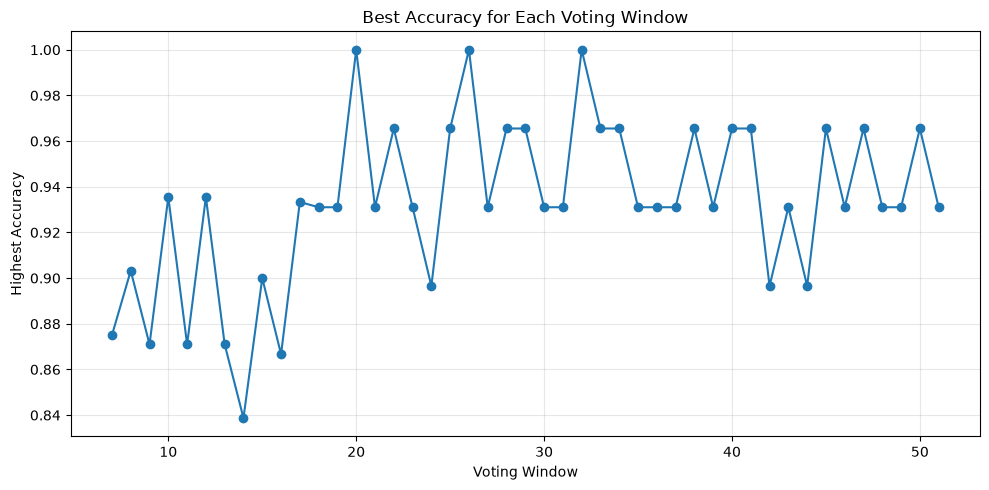

In [57]:
best_per_window = (
    metric_df.loc[
        metric_df.groupby("voting_window")["accuracy"].idxmax()
    ]
    .sort_values("voting_window")
)

plt.figure(figsize=(10, 5))

plt.plot(
    best_per_window["voting_window"],
    best_per_window["accuracy"],
    marker="o"
)

plt.xlabel("Voting Window")
plt.ylabel("Highest Accuracy")
plt.title("Best Accuracy for Each Voting Window")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [58]:
metric_df.sort_values("accuracy", ascending=False).head(35)

,accuracy,missclassified,total_device_count,iot_device_count,non_iot_device_count,dropped_iot_devices,dropped_non_iot_device,voting_window,threshold
272,1.000000,[],29,20,9,"[(74:6a:89:00:2e:25, Blipcare Blood Pressure meter), (18:b4:30:25:be:e4, NEST Protect smoke alarm), (00:24:e4:1b:6f:96, Withings Smart scale)]","[(8a:05:81:fa:cc:14, unknown), (d2:13:91:23:2a:58, unknown)]",26,0.60
271,1.000000,[],29,20,9,"[(74:6a:89:00:2e:25, Blipcare Blood Pressure meter), (18:b4:30:25:be:e4, NEST Protect smoke alarm), (00:24:e4:1b:6f:96, Withings Smart scale)]","[(8a:05:81:fa:cc:14, unknown), (d2:13:91:23:2a:58, unknown)]",26,0.55
359,1.000000,[],29,20,9,"[(74:6a:89:00:2e:25, Blipcare Blood Pressure meter), (18:b4:30:25:be:e4, NEST Protect smoke alarm), (00:24:e4:1b:6f:96, Withings Smart scale)]","[(8a:05:81:fa:cc:14, unknown), (d2:13:91:23:2a:58, unknown)]",32,0.75
192,1.000000,[],29,20,9,"[(74:6a:89:00:2e:25, Blipcare Blood Pressure meter), (18:b4:30:25:be:e4, NEST Protect smoke alarm), (00:24:e4:1b:6f:96, Withings Smart scale)]","[(8a:05:81:fa:cc:14, unknown), (d2:13:91:23:2a:58, unknown)]",20,0.80
483,0.965517,[30:8c:fb:b6:ea:45],29,20,9,"[(74:6a:89:00:2e:25, Blipcare Blood Pressure meter), (18:b4:30:25:be:e4, NEST Protect smoke alarm), (00:24:e4:1b:6f:96, Withings Smart scale)]","[(8a:05:81:fa:cc:14, unknown), (d2:13:91:23:2a:58, unknown)]",41,0.65
482,0.965517,[30:8c:fb:b6:ea:45],29,20,9,"[(74:6a:89:00:2e:25, Blipcare Blood Pressure meter), (18:b4:30:25:be:e4, NEST Protect smoke alarm), (00:24:e4:1b:6f:96, Withings Smart scale)]","[(8a:05:81:fa:cc:14, unknown), (d2:13:91:23:2a:58, unknown)]",41,0.60
386,0.965517,[30:8c:fb:b6:ea:45],29,20,9,"[(74:6a:89:00:2e:25, Blipcare Blood Pressure meter), (18:b4:30:25:be:e4, NEST Protect smoke alarm), (00:24:e4:1b:6f:96, Withings Smart scale)]","[(8a:05:81:fa:cc:14, unknown), (d2:13:91:23:2a:58, unknown)]",34,0.70
303,0.965517,[e0:76:d0:33:bb:85],29,20,9,"[(74:6a:89:00:2e:25, Blipcare Blood Pressure meter), (18:b4:30:25:be:e4, NEST Protect smoke alarm), (00:24:e4:1b:6f:96, Withings Smart scale)]","[(8a:05:81:fa:cc:14, unknown), (d2:13:91:23:2a:58, unknown)]",28,0.75
539,0.965517,[00:24:e4:10:ee:4c],29,20,9,"[(74:6a:89:00:2e:25, Blipcare Blood Pressure meter), (18:b4:30:25:be:e4, NEST Protect smoke alarm), (00:24:e4:1b:6f:96, Withings Smart scale)]","[(8a:05:81:fa:cc:14, unknown), (d2:13:91:23:2a:58, unknown)]",45,0.65
611,0.965517,[e0:76:d0:33:bb:85],29,20,9,"[(74:6a:89:00:2e:25, Blipcare Blood Pressure meter), (18:b4:30:25:be:e4, NEST Protect smoke alarm), (00:24:e4:1b:6f:96, Withings Smart scale)]","[(8a:05:81:fa:cc:14, unknown), (d2:13:91:23:2a:58, unknown)]",50,0.75
